# **Setup (Instação das bibliotecas, etc)**

In [ ]:
from google.colab import auth
import gspread
from google.auth import default
import pandas as pd

#autenticacao
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# **Abrir o Sheets com os dados coletados.**

In [ ]:
sh = gc.open_by_url("https://docs.google.com/spreadsheets/d/1nJxvK-CYToxpa3qgZG_y2KsIpvY0wDAIgJDJq0gfdXU/edit?gid=0#gid=0")
#worksheet = sh.get_worksheet(0) usado em esp8266
worksheet = sh.worksheet("esp32")


In [ ]:
rows = worksheet.get_all_values()

#colunas = ["label", "ssid", "bssid", "rssi_dbm", "snr_db", "sample_id"] usado em esp8266
colunas = ["label", "ssid", "bssid", "rssi_dbm", "sample_id"]

# descarta a primeira linha se for o cabecalho (compara com os nomes esperados)
if rows[0] == colunas:
    df = pd.DataFrame(rows[1:], columns=colunas)
else:
    df = pd.DataFrame(rows, columns=colunas)

#for col in ["rssi_dbm", "snr_db", "sample_id"]: usado em esp8266
    #df[col] = pd.to_numeric(df[col], errors="coerce") usado em esp8266

for col in ["rssi_dbm", "sample_id"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna()

df.head()

,label,ssid,bssid,rssi_dbm,sample_id
0,eHealth_p05,WLL-Inatel,D0:4F:58:52:D2:30,-51,0
1,eHealth_p05,WLL-Inatel,D0:4F:58:52:D4:80,-65,0
2,eHealth_p05,WLL-Inatel,D0:4F:58:52:D5:A0,-68,0
3,eHealth_p05,WLL-Inatel,B4:79:C8:05:B9:38,-73,0
4,eHealth_p05,WLL-Inatel,80:BC:37:63:F5:60,-76,0


In [ ]:
df.head()

,label,ssid,bssid,rssi_dbm,sample_id
0,eHealth_p05,WLL-Inatel,D0:4F:58:52:D2:30,-51,0
1,eHealth_p05,WLL-Inatel,D0:4F:58:52:D4:80,-65,0
2,eHealth_p05,WLL-Inatel,D0:4F:58:52:D5:A0,-68,0
3,eHealth_p05,WLL-Inatel,B4:79:C8:05:B9:38,-73,0
4,eHealth_p05,WLL-Inatel,80:BC:37:63:F5:60,-76,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24778 entries, 0 to 24777
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   label      24778 non-null  object
 1   ssid       24778 non-null  object
 2   bssid      24778 non-null  object
 3   rssi_dbm   24778 non-null  int64 
 4   sample_id  24778 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 968.0+ KB


# **Verificar sample_id**

In [ ]:
print("Quantidade de samples:", df["sample_id"].nunique())

print("\nSamples por label:")
print(df.groupby("label")["sample_id"].nunique())

Quantidade de samples: 2638

Samples por label:
label
eHealth_p01    492
eHealth_p02    511
eHealth_p03    531
eHealth_p04    522
eHealth_p05    582
Name: sample_id, dtype: int64


# **Ver quantos BSSIDs existem**

In [ ]:
print("BSSIDs únicos:", df["bssid"].nunique())

print("\nBSSIDs:")
print(df["bssid"].unique())

BSSIDs únicos: 22

BSSIDs:
['D0:4F:58:52:D2:30' 'D0:4F:58:52:D4:80' 'D0:4F:58:52:D5:A0'
 'B4:79:C8:05:B9:38' '80:BC:37:63:F5:60' 'D0:4F:58:52:D5:20'
 '80:BC:37:63:F4:60' '80:BC:37:64:09:70' 'B4:79:C8:05:BC:88'
 'B4:79:C8:05:B9:B8' 'F0:6F:CE:40:76:10' '30:87:D9:01:4E:48'
 '80:BC:37:63:AF:20' '30:87:D9:01:4E:58' '30:87:D9:01:4B:28'
 '20:58:69:0E:A0:18' 'B4:79:C8:05:C6:38' 'D0:4F:58:52:D2:C0'
 'D0:4F:58:52:D2:B0' '20:58:69:0E:A0:38' 'B4:79:C8:05:C1:F8'
 '30:87:D9:02:FE:08']


# **Ver quantos APs existem em cada sample**

In [ ]:
aps_por_sample = (
    df.groupby("sample_id")["bssid"]
      .nunique()
)

print(aps_por_sample.describe())

count    2638.000000
mean        9.392722
std         1.833942
min         3.000000
25%         8.000000
50%         9.000000
75%        11.000000
max        15.000000
Name: bssid, dtype: float64


# **Fazer o pivot**

In [ ]:
fingerprints = df.pivot_table(
    index=["sample_id", "label"],
    columns="bssid",
    values="rssi_dbm",
    aggfunc="mean"
)

In [ ]:
fingerprints = fingerprints.reset_index()

In [ ]:
fingerprints.head()

bssid,sample_id,label,20:58:69:0E:A0:18,20:58:69:0E:A0:38,30:87:D9:01:4B:28,30:87:D9:01:4E:48,30:87:D9:01:4E:58,30:87:D9:02:FE:08,80:BC:37:63:AF:20,80:BC:37:63:F4:60,...,B4:79:C8:05:BC:88,B4:79:C8:05:C1:F8,B4:79:C8:05:C6:38,D0:4F:58:52:D2:30,D0:4F:58:52:D2:B0,D0:4F:58:52:D2:C0,D0:4F:58:52:D4:80,D0:4F:58:52:D5:20,D0:4F:58:52:D5:A0,F0:6F:CE:40:76:10
0,0,eHealth_p05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-77.0,...,-85.0,NaN,NaN,-51.0,NaN,NaN,-65.0,-76.0,-68.0,-91.0
1,1,eHealth_p05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-81.0,...,-86.0,NaN,NaN,-52.0,NaN,NaN,-64.0,-78.0,-66.0,-88.0
2,2,eHealth_p05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-81.0,...,-87.0,NaN,NaN,-51.0,NaN,NaN,-65.0,-82.0,-66.0,-87.0
3,3,eHealth_p05,NaN,NaN,NaN,-89.0,NaN,NaN,NaN,-80.0,...,NaN,NaN,NaN,-52.0,NaN,NaN,-69.0,-81.0,-67.0,-91.0
4,4,eHealth_p05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-77.0,...,-89.0,NaN,NaN,-50.0,NaN,NaN,-67.0,-82.0,-66.0,-90.0


# **DATA CLEASING**

In [ ]:
fingerprints = fingerprints.fillna(-100)

# **Separar X e Y**

In [ ]:
X = fingerprints.drop(columns=["sample_id", "label"])

y = fingerprints["label"]

In [ ]:
print("X:", X.shape)
print("y:", y.shape)

X: (2638, 22)
y: (2638,)


In [ ]:
X.head()

bssid,20:58:69:0E:A0:18,20:58:69:0E:A0:38,30:87:D9:01:4B:28,30:87:D9:01:4E:48,30:87:D9:01:4E:58,30:87:D9:02:FE:08,80:BC:37:63:AF:20,80:BC:37:63:F4:60,80:BC:37:63:F5:60,80:BC:37:64:09:70,...,B4:79:C8:05:BC:88,B4:79:C8:05:C1:F8,B4:79:C8:05:C6:38,D0:4F:58:52:D2:30,D0:4F:58:52:D2:B0,D0:4F:58:52:D2:C0,D0:4F:58:52:D4:80,D0:4F:58:52:D5:20,D0:4F:58:52:D5:A0,F0:6F:CE:40:76:10
0,-100.0,-100.0,-100.0,-100.0,-100.0,-100.0,-100.0,-77.0,-76.0,-84.0,...,-85.0,-100.0,-100.0,-51.0,-100.0,-100.0,-65.0,-76.0,-68.0,-91.0
1,-100.0,-100.0,-100.0,-100.0,-100.0,-100.0,-100.0,-81.0,-76.0,-79.0,...,-86.0,-100.0,-100.0,-52.0,-100.0,-100.0,-64.0,-78.0,-66.0,-88.0
2,-100.0,-100.0,-100.0,-100.0,-100.0,-100.0,-100.0,-81.0,-79.0,-81.0,...,-87.0,-100.0,-100.0,-51.0,-100.0,-100.0,-65.0,-82.0,-66.0,-87.0
3,-100.0,-100.0,-100.0,-89.0,-100.0,-100.0,-100.0,-80.0,-80.0,-86.0,...,-100.0,-100.0,-100.0,-52.0,-100.0,-100.0,-69.0,-81.0,-67.0,-91.0
4,-100.0,-100.0,-100.0,-100.0,-100.0,-100.0,-100.0,-77.0,-86.0,-90.0,...,-89.0,-100.0,-100.0,-50.0,-100.0,-100.0,-67.0,-82.0,-66.0,-90.0


In [ ]:
y.head()

,label
0,eHealth_p05
1,eHealth_p05
2,eHealth_p05
3,eHealth_p05
4,eHealth_p05


# **Feature Selection**

In [ ]:
# ── Sem Feature Selection - usando todos os 13 BSSIDs ────────────────────────
feature_cols = [c for c in fingerprints.columns if c not in ["sample_id", "label"]]

X = fingerprints[feature_cols]
y = fingerprints["label"]

print("BSSIDs utilizados:", len(feature_cols))
print("Shape de X:", X.shape)
print("Shape de y:", y.shape)

BSSIDs utilizados: 22
Shape de X: (2638, 22)
Shape de y: (2638,)


# **Normalizacao Min-Max**

In [ ]:
# ── Normalizacao Min-Max ──────────────────────────────────────────────────────
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

print("Valores antes:", X.values.min(), "max:", X.values.max())
print("Valores apos - min:", X_scaled.min().round(2), "max:", X_scaled.max().round(2))

Valores antes: -100.0 max: -36.0
Valores apos - min: 0.0 max: 1.0


# **Split de treino (70/30)**

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y,
    test_size=0.30,
    random_state=42,
    stratify=y   # garante proporcao igual dos 3 labels em treino e teste
)

print("Treino:", X_train.shape, "| Teste:", X_test.shape)
print("\nDistribuicao treino:")
print(y_train.value_counts())
print("\nDistribuicao teste:")
print(y_test.value_counts())

Treino: (1846, 22) | Teste: (792, 22)

Distribuicao treino:
label
eHealth_p05    407
eHealth_p03    372
eHealth_p04    365
eHealth_p02    358
eHealth_p01    344
Name: count, dtype: int64

Distribuicao teste:
label
eHealth_p05    175
eHealth_p03    159
eHealth_p04    157
eHealth_p02    153
eHealth_p01    148
Name: count, dtype: int64


# **Treino KNN**

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

acc = accuracy_score(y_test, y_pred)
f1  = f1_score(y_test, y_pred, average="weighted")

print(f"Acuracia: {acc*100:.2f}%")
print(f"F1 Score: {f1*100:.2f}%")
print("\nRelatorio completo:")
print(classification_report(y_test, y_pred))

Acuracia: 98.11%
F1 Score: 98.11%

Relatorio completo:
              precision    recall  f1-score   support

 eHealth_p01       0.96      0.97      0.96       148
 eHealth_p02       0.95      0.96      0.96       153
 eHealth_p03       0.99      0.99      0.99       159
 eHealth_p04       0.99      0.99      0.99       157
 eHealth_p05       1.00      1.00      1.00       175

    accuracy                           0.98       792
   macro avg       0.98      0.98      0.98       792
weighted avg       0.98      0.98      0.98       792



# **Matriz de confusão**

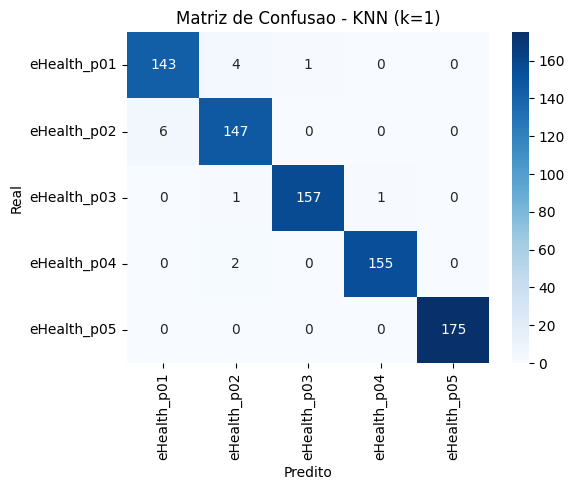

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=knn.classes_)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=knn.classes_,
            yticklabels=knn.classes_)
plt.xlabel("Predito")
plt.ylabel("Real")
plt.title("Matriz de Confusao - KNN (k=1)")
plt.tight_layout()
plt.show()

# **Testar diferentes valores de K**

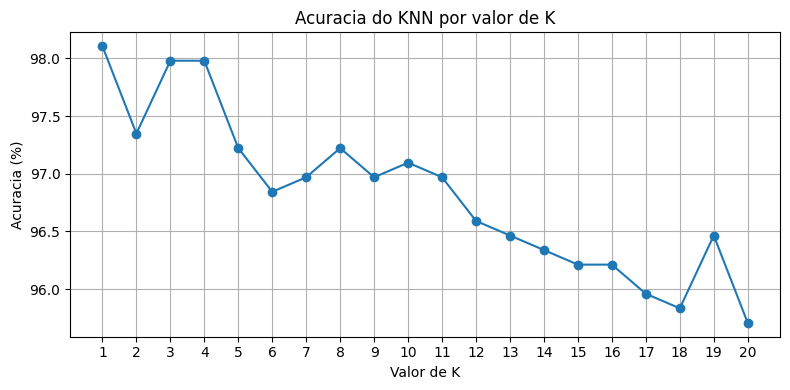

Melhor K: 1 com 98.11% de acuracia


In [ ]:
#util para encontrar o melhor K para o seu dataset especifico

resultados_k = []

for k in range(1, 21):
    modelo = KNeighborsClassifier(n_neighbors=k)
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    resultados_k.append({
        "k": k,
        "acuracia": accuracy_score(y_test, pred) * 100
    })

import pandas as pd
df_k = pd.DataFrame(resultados_k)

plt.figure(figsize=(8, 4))
plt.plot(df_k["k"], df_k["acuracia"], marker="o")
plt.xlabel("Valor de K")
plt.ylabel("Acuracia (%)")
plt.title("Acuracia do KNN por valor de K")
plt.xticks(range(1, 21))
plt.grid(True)
plt.tight_layout()
plt.show()

melhor = df_k.loc[df_k["acuracia"].idxmax()]
print(f"Melhor K: {int(melhor['k'])} com {melhor['acuracia']:.2f}% de acuracia")

# **Treino com Random Forest**

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, max_depth=100, random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

acc_rf = accuracy_score(y_test, y_pred_rf)
f1_rf  = f1_score(y_test, y_pred_rf, average="weighted")

print(f"Acuracia: {acc_rf*100:.2f}%")
print(f"F1 Score: {f1_rf*100:.2f}%")
print("\nRelatorio completo:")
print(classification_report(y_test, y_pred_rf))

Acuracia: 99.87%
F1 Score: 99.87%

Relatorio completo:
              precision    recall  f1-score   support

 eHealth_p01       1.00      0.99      1.00       148
 eHealth_p02       0.99      1.00      1.00       153
 eHealth_p03       1.00      1.00      1.00       159
 eHealth_p04       1.00      1.00      1.00       157
 eHealth_p05       1.00      1.00      1.00       175

    accuracy                           1.00       792
   macro avg       1.00      1.00      1.00       792
weighted avg       1.00      1.00      1.00       792



# **Matriz de Confusão RF**

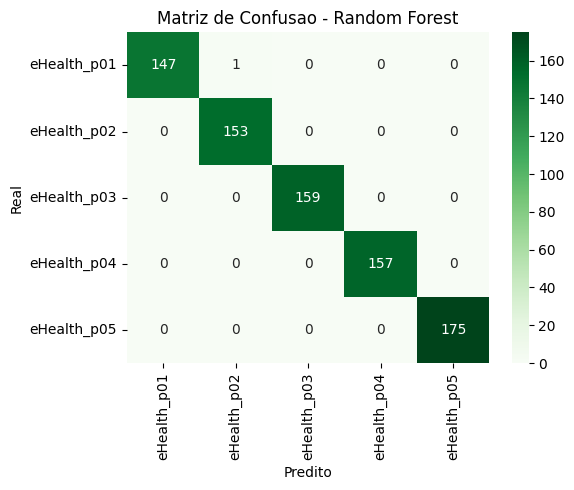

In [ ]:
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=rf.classes_)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Greens",
            xticklabels=rf.classes_,
            yticklabels=rf.classes_)
plt.xlabel("Predito")
plt.ylabel("Real")
plt.title("Matriz de Confusao - Random Forest")
plt.tight_layout()
plt.show()

# **Validação Cruzada**

In [ ]:
#Validacao Cruzada (5-fold)
from sklearn.model_selection import cross_val_score

#KNN
scores_knn = cross_val_score(
    KNeighborsClassifier(n_neighbors=7),
    X_scaled, y, cv=5, scoring="accuracy"
)

#random Forest
scores_rf = cross_val_score(
    RandomForestClassifier(n_estimators=200, max_depth=100, random_state=42),
    X_scaled, y, cv=5, scoring="accuracy"
)

print("KNN - Acuracia por fold:", (scores_knn * 100).round(2))
print(f"KNN - Media: {scores_knn.mean()*100:.2f}% | Desvio: {scores_knn.std()*100:.2f}%")

print("\nRandom Forest - Acuracia por fold:", (scores_rf * 100).round(2))
print(f"RF  - Media: {scores_rf.mean()*100:.2f}% | Desvio: {scores_rf.std()*100:.2f}%")

KNN - Acuracia por fold: [89.2  92.8  98.67 97.91 97.91]
KNN - Media: 95.30% | Desvio: 3.70%

Random Forest - Acuracia por fold: [ 99.62 100.   100.   100.   100.  ]
RF  - Media: 99.92% | Desvio: 0.15%


# **Salvar o modelo treinado**

In [ ]:
import joblib

joblib.dump(rf, "modelo_rf_inatel.pkl")
joblib.dump(scaler, "scaler_inatel.pkl")

print("Modelo e scaler salvos.")

Modelo e scaler salvos.


In [ ]:
print(list(X.columns))

['20:58:69:0E:A0:18', '20:58:69:0E:A0:38', '30:87:D9:01:4B:28', '30:87:D9:01:4E:48', '30:87:D9:01:4E:58', '30:87:D9:02:FE:08', '80:BC:37:63:AF:20', '80:BC:37:63:F4:60', '80:BC:37:63:F5:60', '80:BC:37:64:09:70', 'B4:79:C8:05:B9:38', 'B4:79:C8:05:B9:B8', 'B4:79:C8:05:BC:88', 'B4:79:C8:05:C1:F8', 'B4:79:C8:05:C6:38', 'D0:4F:58:52:D2:30', 'D0:4F:58:52:D2:B0', 'D0:4F:58:52:D2:C0', 'D0:4F:58:52:D4:80', 'D0:4F:58:52:D5:20', 'D0:4F:58:52:D5:A0', 'F0:6F:CE:40:76:10']
